In [31]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [32]:
usuario = "matias.palma1@mail.udp.cl"
password = "Mati.10042003"


Imacec empalmado

In [33]:
codigo = "F032.IMC.IND.Z.Z.EP18.Z.Z.0.M"

In [34]:
url = (
    "https://si3.bcentral.cl/SieteRestWS/SieteRestWS.ashx?"
    f"user={usuario}"
    f"&pass={password}"
    "&function=GetSeries"
    f"&timeseries={codigo}"
)

In [35]:
respuesta = requests.get(url)

print(respuesta.status_code)

200


In [36]:
datos = respuesta.json()

datos.keys()

dict_keys(['Codigo', 'Descripcion', 'Series', 'SeriesInfos'])

In [37]:
datos

{'Codigo': 0,
 'Descripcion': 'Success',
 'Series': {'descripEsp': 'Imacec empalmado, serie original (índice 2018=100)',
  'descripIng': 'Monthly indicator of economic activity Imacec,  linked series (2018 index=100)',
  'seriesId': 'F032.IMC.IND.Z.Z.EP18.Z.Z.0.M',
  'Obs': [{'indexDateString': '01-01-1996',
    'value': '42.487431369417',
    'statusCode': 'OK'},
   {'indexDateString': '01-02-1996',
    'value': '41.164549016881',
    'statusCode': 'OK'},
   {'indexDateString': '01-03-1996',
    'value': '44.717816536594',
    'statusCode': 'OK'},
   {'indexDateString': '01-04-1996',
    'value': '43.672806351396',
    'statusCode': 'OK'},
   {'indexDateString': '01-05-1996',
    'value': '43.487324742889',
    'statusCode': 'OK'},
   {'indexDateString': '01-06-1996',
    'value': '41.867915080919',
    'statusCode': 'OK'},
   {'indexDateString': '01-07-1996',
    'value': '41.448824430024',
    'statusCode': 'OK'},
   {'indexDateString': '01-08-1996',
    'value': '42.05654343401',
 

In [38]:
obs = datos['Series']['Obs']

df_imacec = pd.DataFrame(obs)

df_imacec.head()

,indexDateString,value,statusCode
0,01-01-1996,42.487431369417,OK
1,01-02-1996,41.164549016881,OK
2,01-03-1996,44.717816536594,OK
3,01-04-1996,43.672806351396,OK
4,01-05-1996,43.487324742889,OK


In [39]:
df_imacec = df_imacec[['indexDateString', 'value']]

df_imacec.columns = ['fecha', 'imacec']

In [40]:
df_imacec['fecha'] = pd.to_datetime(
    df_imacec['fecha'],
    dayfirst=True
)

df_imacec['imacec'] = pd.to_numeric(
    df_imacec['imacec']
)

In [41]:
df_imacec.info()

<class 'pandas.DataFrame'>
RangeIndex: 368 entries, 0 to 367
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   fecha   368 non-null    datetime64[us]
 1   imacec  368 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 5.9 KB


In [42]:
df_imacec.head()

,fecha,imacec
0,1996-01-01,42.487431
1,1996-02-01,41.164549
2,1996-03-01,44.717817
3,1996-04-01,43.672806
4,1996-05-01,43.487325


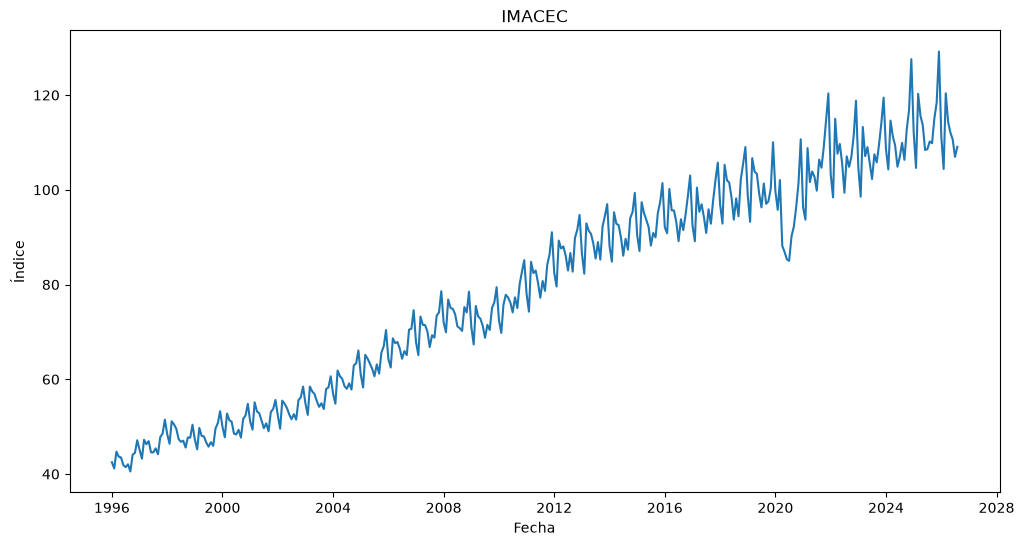

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    df_imacec['fecha'],
    df_imacec['imacec']
)

plt.title('IMACEC')
plt.xlabel('Fecha')
plt.ylabel('Índice')

plt.show()

In [44]:
import requests
import pandas as pd

def descargar_serie(codigo, usuario, password):
    
    url = (
        "https://si3.bcentral.cl/SieteRestWS/SieteRestWS.ashx?"
        f"user={usuario}"
        f"&pass={password}"
        "&function=GetSeries"
        f"&timeseries={codigo}"
    )

    respuesta = requests.get(url)
    datos = respuesta.json()

    obs = datos['Series']['Obs']

    df = pd.DataFrame(obs)

    df = df[['indexDateString', 'value']]

    df.columns = ['fecha', 'valor']

    df['fecha'] = pd.to_datetime(
        df['fecha'],
        dayfirst=True
    )

    df['valor'] = pd.to_numeric(df['valor'])

    return df

In [45]:
codigo_imacec = "F032.IMC.IND.Z.Z.EP18.Z.Z.0.M"

df_imacec = descargar_serie(
    codigo_imacec,
    usuario,
    password
)

df_imacec.head()

,fecha,valor
0,1996-01-01,42.487431
1,1996-02-01,41.164549
2,1996-03-01,44.717817
3,1996-04-01,43.672806
4,1996-05-01,43.487325


fin por ahora